# LangGraph: Planning and Reflection Agents
### Instructor-ready hands-on notebook | Beginner → Intermediate

**Learning outcomes:** explain graph state, nodes, edges, conditional routing, planning, executing, critiquing, revising, and termination.

**LangChain + OpenAI integration:** This notebook uses `langchain_openai.ChatOpenAI` as the actual LLM for planning, execution, replanning, drafting, and critique.

**Four demonstrations:**
1. **Planning without an LLM** — observe the graph mechanics (no API key).
2. **LLM-powered Plan → Execute → Replan** — break a training task into actionable steps.
3. **Reflection loop** — draft → critique → revise until accepted or budget exhausted.
4. **Combined Planning + Reflection** — plan first, review the deliverable, then improve it.

> **Source note:** The shared Google Doc was not accessible through the connected Drive account (404). This is therefore an independently created notebook on the requested topics, not a transcription of that document.

**Cost:** Demo 1 uses no model. Demos 2–4 call an OpenAI-compatible chat model and may incur API charges. Outputs vary.

## The core mental model

- **State**: the shared data passed from node to node.
- **Node**: a Python function that receives state and returns a **partial state update**.
- **Edge**: a fixed transition.
- **Conditional edge**: a function that decides the next node.
- **Planning**: decide which steps to perform, then execute them; optionally replan after seeing results.
- **Reflection**: create an artifact, critique it, then revise it.
- **Bounded loop**: always set a maximum number of iterations to avoid runaway cost.

**Planning** asks *“What should I do next?”*; **reflection** asks *“Is my output good enough, and what should change?”*.

In [ ]:
%pip install -q -U langgraph langchain-openai pydantic python-dotenv ipython

In [7]:
from typing import TypedDict, Literal
from IPython.display import display, Markdown, Image
from langgraph.graph import StateGraph, START, END
import os

def show_graph(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("Graph preview unavailable:", e)
        print(graph.get_graph().draw_mermaid())

def show_events(graph, input_state):
    for event in graph.stream(input_state, stream_mode="updates"):
        print(event)

In [9]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel, Field

load_dotenv()
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
HAS_OPENAI_KEY = bool(os.getenv("OPENAI_API_KEY"))

# Real LangChain OpenAI chat model: initialized ONCE and shared by every LangGraph node.
llm = (
    ChatOpenAI(
        model=MODEL_NAME,
        temperature=0,
        timeout=60,
        max_retries=2,
    )
    if HAS_OPENAI_KEY else None
)

def require_llm():
    if llm is None:
        raise RuntimeError("Missing OPENAI_API_KEY. Set the key and rerun this setup cell.")
    return llm

print(f"OpenAI model: {MODEL_NAME}")
print(f"LLM ready: {HAS_OPENAI_KEY}")

# Optional real API smoke test (one short model call):
if HAS_OPENAI_KEY:
    test = llm.invoke([HumanMessage(content="Reply with exactly: LangGraph LLM ready")])
    print("API smoke test:", test.content)
else:
    print("Add OPENAI_API_KEY to run Demos 2–4. Demo 1 works offline.")


OpenAI model: gpt-4o-mini
LLM ready: True
API smoke test: LangGraph LLM ready


# Demo 2 — LLM Planning → Execute → Replan

**Business task:** Prepare a beginner-friendly 45-minute workshop on RAG.

1. **Planner:** returns a small structured list of steps.
2. **Executor:** completes **one** step per invocation.
3. **Replanner:** uses the finished work to decide what still needs doing.
4. **Router:** ends after completion or a hard execution budget.

Here an execution step means generating a concrete text deliverable; it is **not** browsing the internet or taking an external action. This distinction matters for real agents.

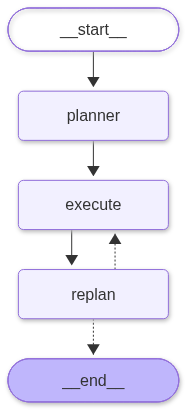

In [ ]:
class StepPlan(BaseModel):
    steps: list[str] = Field(description="Ordered, specific, executable steps")

class ReplanDecision(BaseModel):
    remaining_steps: list[str] = Field(description="Steps still needed, or [] when complete")
    reason: str = Field(description="Short explanation")

class PlanningState(TypedDict):
    objective: str
    plan: list[str]
    completed: list[str]
    artifacts: list[str]
    iterations: int
    max_iterations: int
    decision_reason: str

def planning_node(state: PlanningState):
    planner = require_llm().with_structured_output(StepPlan)
    result = planner.invoke(
        "Design 3 concise, sequential steps for this task. Each step should "
        "produce a small, tangible teaching deliverable. "
        f"Task: {state['objective']}"
    )
    if not result.steps:
        raise ValueError("Planner returned zero steps")
    return {"plan": result.steps}

def execution_node(state: PlanningState):
    if not state["plan"]:
        return {}
    current = state["plan"][0]
    reply = require_llm().invoke(
        "Complete exactly this one step as a concise, useful deliverable. "
        "Do not claim you searched the web or ran external tools.\n"
        f"Overall objective: {state['objective']}\n"
        f"Current step: {current}\n"
        f"Work already done: {state['artifacts']}"
    )
    artifact = str(reply.content)
    print(f"\nEXECUTED: {current}\n{artifact[:450]}\n")
    return {
        "completed": state["completed"] + [current],
        "artifacts": state["artifacts"] + [artifact],
        "plan": state["plan"][1:],
        "iterations": state["iterations"] + 1
    }

def replan_node(state: PlanningState):
    if not state["plan"]:
        return {"decision_reason": "All original steps executed"}
    replanner = require_llm().with_structured_output(ReplanDecision)
    decision = replanner.invoke(
        "Given the objective, completed steps, and still planned steps, "
        "return ONLY the genuinely needed remaining tasks. Do not repeat completed tasks. "
        "Keep at most 3 remaining steps. Return [] if the objective is complete.\n"
        f"Objective: {state['objective']}\n"
        f"Completed: {state['completed']}\n"
        f"Pending: {state['plan']}\n"
        f"Artifacts: {[x[:300] for x in state['artifacts']]}"
    )
    return {
        "plan": decision.remaining_steps[:3],
        "decision_reason": decision.reason
    }

def route_planning(state: PlanningState) -> Literal["execute", "__end__"]:
    if state["iterations"] >= state["max_iterations"] or not state["plan"]:
        return END
    return "execute"

planning_builder = StateGraph(PlanningState)
planning_builder.add_node("planner", planning_node)
planning_builder.add_node("execute", execution_node)
planning_builder.add_node("replan", replan_node)
planning_builder.add_edge(START, "planner")
planning_builder.add_edge("planner", "execute")
planning_builder.add_edge("execute", "replan")
planning_builder.add_conditional_edges(
    "replan", route_planning, {"execute": "execute", END: END}
)
planning_graph = planning_builder.compile()
show_graph(planning_graph)

In [11]:
if HAS_OPENAI_KEY:
    planning_result = planning_graph.invoke(
        {
            "objective": "Prepare a beginner-friendly 45-minute workshop on RAG",
            "plan": [], "completed": [], "artifacts": [],
            "iterations": 0, "max_iterations": 4, "decision_reason": "",
        },
        config={"recursion_limit": 25},
    )
    print("Completed steps:", planning_result["completed"])
    print("Unfinished steps:", planning_result["plan"])
    print("Stop reason:", planning_result["decision_reason"])
    for i, artifact in enumerate(planning_result["artifacts"], 1):
        display(Markdown(f"### Executed deliverable {i}\n\n{artifact}"))
else:
    print("Skipped Demo 2: configure OPENAI_API_KEY in the setup cell first.")



EXECUTED: Define the objectives and key concepts of RAG (Retrieval-Augmented Generation) to ensure clarity for beginners. Create a one-page handout summarizing these objectives and concepts, including definitions and examples.
### One-Page Handout: Introduction to Retrieval-Augmented Generation (RAG)

---

#### Objectives of the Workshop:
1. **Understand RAG**: Introduce the concept of Retrieval-Augmented Generation and its significance in natural language processing.
2. **Explore Components**: Break down the key components of RAG, including retrieval and generation processes.
3. **Hands-On Example**: Provide a practical example of how RAG can be applied in real-world 


EXECUTED: Develop a simple presentation (10-15 slides) that outlines the workshop structure, key points, and visual aids to facilitate understanding of RAG. Include interactive elements such as questions or polls to engage participants.
### Presentation Outline for RAG Workshop

#### Slide 1: Title Slide
- Title: Intr

### Executed deliverable 1

### One-Page Handout: Introduction to Retrieval-Augmented Generation (RAG)

---

#### Objectives of the Workshop:
1. **Understand RAG**: Introduce the concept of Retrieval-Augmented Generation and its significance in natural language processing.
2. **Explore Components**: Break down the key components of RAG, including retrieval and generation processes.
3. **Hands-On Example**: Provide a practical example of how RAG can be applied in real-world scenarios.
4. **Discuss Applications**: Highlight various applications of RAG in different fields such as customer service, content creation, and research.

---

#### Key Concepts of RAG:

1. **Definition of RAG**:
   - Retrieval-Augmented Generation (RAG) is a framework that combines information retrieval and text generation. It retrieves relevant documents from a knowledge base and uses them to generate coherent and contextually relevant responses.

2. **Components of RAG**:
   - **Retrieval Component**: This part of the system searches a database or corpus to find relevant documents or pieces of information based on a given query.
   - **Generation Component**: After retrieving the relevant information, this component generates a response or text that incorporates the retrieved data, ensuring it is coherent and contextually appropriate.

3. **How RAG Works**:
   - **Step 1**: A user inputs a query or prompt.
   - **Step 2**: The retrieval system searches for relevant documents.
   - **Step 3**: The generation model uses the retrieved documents to create a response that answers the query.

4. **Example of RAG in Action**:
   - **Scenario**: A user asks, "What are the benefits of exercise?"
   - **Retrieval**: The system retrieves articles and studies related to exercise benefits.
   - **Generation**: The model synthesizes the information and generates a response like: "Exercise improves physical health, boosts mental well-being, and enhances overall quality of life."

5. **Applications of RAG**:
   - **Customer Support**: Providing accurate answers to customer inquiries by retrieving relevant FAQs and generating responses.
   - **Content Creation**: Assisting writers by retrieving information and generating drafts based on specific topics.
   - **Research Assistance**: Helping researchers find and summarize relevant literature quickly.

---

#### Conclusion:
RAG represents a powerful approach to enhancing the capabilities of AI systems by combining the strengths of information retrieval and natural language generation. Understanding its components and applications will empower participants to leverage RAG in various contexts.

--- 

**Note**: This handout serves as a foundational resource for participants to grasp the essentials of RAG and prepare for interactive discussions and activities during the workshop.

### Executed deliverable 2

### Presentation Outline for RAG Workshop

#### Slide 1: Title Slide
- Title: Introduction to Retrieval-Augmented Generation (RAG)
- Subtitle: A Beginner-Friendly Workshop
- Date and Presenter Name

#### Slide 2: Workshop Objectives
- Understand RAG and its significance
- Explore key components: retrieval and generation
- Provide a hands-on example
- Discuss various applications of RAG

#### Slide 3: What is RAG?
- Definition of Retrieval-Augmented Generation
- Importance in natural language processing

#### Slide 4: Components of RAG
- **Retrieval Component**: Searches for relevant documents
- **Generation Component**: Creates coherent responses using retrieved data

#### Slide 5: How RAG Works
- Step 1: User inputs a query
- Step 2: Retrieval system finds relevant documents
- Step 3: Generation model creates a response

#### Slide 6: Interactive Poll
- Question: "Have you ever used AI for information retrieval?"
- Options: Yes, No, Unsure

#### Slide 7: Example of RAG in Action
- Scenario: User asks about benefits of exercise
- Retrieval: System finds relevant articles
- Generation: Model synthesizes and responds

#### Slide 8: Applications of RAG
- Customer Support: Answering inquiries
- Content Creation: Assisting writers
- Research Assistance: Summarizing literature

#### Slide 9: Group Discussion Prompt
- "What potential applications of RAG can you think of in your field?"

#### Slide 10: Benefits of RAG
- Enhances AI capabilities
- Combines strengths of retrieval and generation
- Provides contextually relevant responses

#### Slide 11: Challenges and Considerations
- Data quality and relevance
- Ethical considerations in AI responses

#### Slide 12: Interactive Q&A Session
- Open floor for participant questions and discussions

#### Slide 13: Summary of Key Points
- Recap of RAG definition, components, and applications

#### Slide 14: Resources for Further Learning
- Suggested readings and online courses on RAG and NLP

#### Slide 15: Thank You!
- Contact information for follow-up questions
- Encourage feedback on the workshop

### Interactive Elements
- Include polls and discussion prompts to engage participants throughout the presentation.
- Encourage questions during the Q&A session to foster interaction and clarify concepts.

### Executed deliverable 3

### Practical Exercise: RAG Application Activity

**Objective:** Allow participants to apply RAG concepts by simulating the retrieval and generation process in small groups.

**Duration:** 15 minutes

**Materials Needed:**
- Pre-selected short articles or snippets of information related to a common topic (e.g., benefits of exercise, climate change, or healthy eating).
- A list of sample queries related to the articles.
- Whiteboard or flip chart for each group to jot down their findings.

**Instructions:**

1. **Group Formation (2 minutes):** 
   - Divide participants into small groups of 3-5 people.

2. **Distribution of Materials (3 minutes):**
   - Provide each group with a set of articles/snippets and a list of sample queries.

3. **Activity Execution (8 minutes):**
   - Each group will:
     - **Step 1:** Choose one query from the list.
     - **Step 2:** Identify relevant information from the provided articles/snippets that can help answer the query (this simulates the retrieval component).
     - **Step 3:** Collaboratively generate a coherent response to the chosen query using the retrieved information (this simulates the generation component).
     - **Step 4:** Write down their response on the whiteboard/flip chart.

4. **Wrap-Up (2 minutes):**
   - Each group briefly presents their query and generated response to the larger group.
   - Encourage participants to discuss the different approaches taken by each group.

**Outcome:** Participants will gain hands-on experience with the RAG process, enhancing their understanding of how retrieval and generation work together to create informative responses.

### Executed deliverable 4

### RAG Workshop Worksheet

---

#### Workshop Title: Introduction to Retrieval-Augmented Generation (RAG)

#### Duration: 45 Minutes

---

### Objectives:
1. **Understand RAG**: Grasp the concept and significance of Retrieval-Augmented Generation in natural language processing.
2. **Explore Components**: Identify and understand the key components of RAG: retrieval and generation.
3. **Hands-On Example**: Engage in a practical exercise to apply RAG concepts.
4. **Discuss Applications**: Recognize various applications of RAG across different fields.

---

### Key Concepts of RAG:

1. **Definition**: RAG combines information retrieval and text generation to produce coherent responses based on retrieved data.
2. **Components**:
   - **Retrieval Component**: Searches for relevant documents based on a query.
   - **Generation Component**: Creates a response using the retrieved information.
3. **Process**:
   - User inputs a query.
   - Retrieval system finds relevant documents.
   - Generation model synthesizes and responds.

---

### Practical Exercise: RAG Application Activity

**Objective**: Simulate the retrieval and generation process in small groups.

**Materials Needed**:
- Pre-selected short articles/snippets on a common topic (e.g., benefits of exercise).
- A list of sample queries related to the articles.
- Whiteboard or flip chart for each group.

**Instructions**:

1. **Group Formation (2 minutes)**:
   - Form groups of 3-5 participants.

2. **Distribution of Materials (3 minutes)**:
   - Provide each group with articles/snippets and a list of queries.

3. **Activity Execution (8 minutes)**:
   - **Step 1**: Choose a query from the list.
   - **Step 2**: Identify relevant information from the articles/snippets (retrieval).
   - **Step 3**: Generate a coherent response using the retrieved information (generation).
   - **Step 4**: Write the response on the whiteboard/flip chart.

4. **Wrap-Up (2 minutes)**:
   - Each group presents their query and response.
   - Discuss different approaches taken by each group.

---

### Expected Outcomes:
- Participants will understand the RAG process through hands-on experience.
- Enhanced comprehension of how retrieval and generation work together.
- Increased awareness of RAG applications in various fields.

---

### Conclusion:
RAG is a powerful framework that enhances AI capabilities by integrating retrieval and generation processes. This workshop aims to equip participants with foundational knowledge and practical skills to leverage RAG in their respective domains.

--- 

**Note**: Use this worksheet as a guide throughout the workshop to stay on track and ensure all objectives are met.

**Instructor observation:** The replanner might change or remove pending steps. `max_iterations` caps the number of execution calls; reaching the cap does **not** guarantee the objective is complete. In production, record a terminal status like `completed` vs `budget_exhausted`, add retries/timeouts, and require authorization for external actions.

# Demo 3 — Reflection: Draft → Critique → Revise

**Scenario:** Write a short explanation of cosine similarity for beginners.

The reviewer returns **structured feedback** with `approved`, `score`, and `improvements`. A conditional edge routes back to **revise** when the draft is insufficient.

**Important nuance:** The same LLM may be biased when grading its own writing. Model-generated approval is a *heuristic*, not a trustworthy quality guarantee.

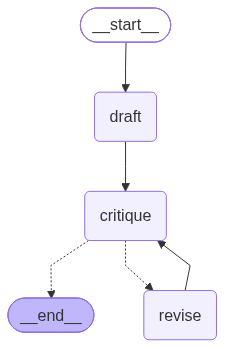

In [6]:
class Review(BaseModel):
    approved: bool = Field(description="Whether all criteria are satisfied")
    score: int = Field(description="Score from 1 to 10")
    improvements: list[str] = Field(description="Actionable revisions, empty when approved")

class ReflectionState(TypedDict):
    task: str
    draft: str
    feedback: list[str]
    approved: bool
    score: int
    revisions: int
    max_revisions: int

def draft_node(state: ReflectionState):
    answer = require_llm().invoke(
        "Produce a clear 150–200 word beginner-facing answer with one numeric example. "
        f"Task: {state['task']}"
    )
    return {"draft": str(answer.content)}

def critique_node(state: ReflectionState):
    reviewer = require_llm().with_structured_output(Review)
    result = reviewer.invoke(
        "Critique the draft against these criteria: correct formula/concept, "
        "one accurate numeric example, beginner-friendly explanation, and no "
        "unsubstantiated claims. Approve only when all criteria are met. "
        "Score from 1 to 10. Supply precise changes where needed.\n"
        f"Task: {state['task']}\nDraft: {state['draft']}"
    )
    # A high score by itself does not override a negative review.
    return {
        "approved": result.approved,
        "score": result.score,
        "feedback": result.improvements
    }

def route_reflection(state: ReflectionState) -> Literal["revise", "__end__"]:
    if state["approved"] or state["revisions"] >= state["max_revisions"]:
        return END
    return "revise"

def revise_node(state: ReflectionState):
    response = require_llm().invoke(
        "Revise the entire answer using all concrete reviewer feedback. "
        "Keep the explanation concise and technically correct.\n"
        f"Original task: {state['task']}\n"
        f"Previous draft: {state['draft']}\n"
        f"Required fixes: {state['feedback']}"
    )
    return {
        "draft": str(response.content),
        "revisions": state["revisions"] + 1
    }

reflection_builder = StateGraph(ReflectionState)
reflection_builder.add_node("draft", draft_node)
reflection_builder.add_node("critique", critique_node)
reflection_builder.add_node("revise", revise_node)
reflection_builder.add_edge(START, "draft")
reflection_builder.add_edge("draft", "critique")
reflection_builder.add_conditional_edges(
    "critique", route_reflection, {"revise": "revise", END: END}
)
reflection_builder.add_edge("revise", "critique")
reflection_graph = reflection_builder.compile()
show_graph(reflection_graph)

In [ ]:
if HAS_OPENAI_KEY:
    reflection_result = reflection_graph.invoke(
        {
            "task": "Explain cosine similarity vs Euclidean distance for text embeddings",
            "draft": "", "feedback": [], "approved": False,
            "score": 0, "revisions": 0, "max_revisions": 2,
        },
        config={"recursion_limit": 15},
    )
    print("Approved:", reflection_result["approved"])
    print("Score:", reflection_result["score"])
    print("Revisions:", reflection_result["revisions"])
    display(Markdown(reflection_result["draft"]))
    if not reflection_result["approved"]:
        print("Stopped without approval; feedback:", reflection_result["feedback"])
else:
    print("Skipped Demo 3: configure OPENAI_API_KEY in the setup cell first.")


# Demo 4 — Planning + Reflection together

This final graph is intentionally small enough for a live classroom demonstration.

```text
START → PLAN → WRITE → REVIEW ── approved or budget exhausted ──→ END
                        ↑         │
                        └─ REVISE ┘
```

**Question:** What is missing from this combined graph? Answer: *step-by-step execution* of individual plan items. Here we create a plan and use it to guide the complete draft. Demo 2 is the genuine plan–execute–replan loop; this demonstration focuses on *how planning and reflection compose*.

In [ ]:
class CombinedState(TypedDict):
    request: str
    outline: list[str]
    output: str
    feedback: list[str]
    accepted: bool
    cycles: int
    max_cycles: int

def combined_plan(s: CombinedState):
    plan = require_llm().with_structured_output(StepPlan).invoke(
        "Produce exactly 3 section titles for a practical response to: " + s["request"]
    )
    return {"outline": plan.steps[:3]}

def combined_write(s: CombinedState):
    response = require_llm().invoke(
        f"Request: {s['request']}\n"
        f"Write an actionable response using this outline: {s['outline']}. "
        "Be accurate and avoid invented statistics."
    )
    return {"output": str(response.content)}

def combined_review(s: CombinedState):
    review = require_llm().with_structured_output(Review).invoke(
        f"Task: {s['request']}\nOutline: {s['outline']}\nDraft: {s['output']}\n"
        "Evaluate completeness, clarity and adherence to outline. "
        "Approve only if all are satisfactory."
    )
    return {"feedback": review.improvements, "accepted": review.approved}

def combined_route(s: CombinedState) -> Literal["revise", "__end__"]:
    return END if s["accepted"] or s["cycles"] >= s["max_cycles"] else "revise"

def combined_revise(s: CombinedState):
    answer = require_llm().invoke(
        f"Improve this draft:\n{s['output']}\n"
        f"Using these comments: {s['feedback']}\n"
        f"Keep the original sections: {s['outline']}"
    )
    return {"output": str(answer.content), "cycles": s["cycles"] + 1}

combined_builder = StateGraph(CombinedState)
for name, fn in [
    ("plan", combined_plan), ("write", combined_write),
    ("review", combined_review), ("revise", combined_revise)
]:
    combined_builder.add_node(name, fn)
combined_builder.add_edge(START, "plan")
combined_builder.add_edge("plan", "write")
combined_builder.add_edge("write", "review")
combined_builder.add_conditional_edges(
    "review", combined_route, {"revise": "revise", END: END}
)
combined_builder.add_edge("revise", "review")
combined_graph = combined_builder.compile()
show_graph(combined_graph)

In [ ]:
if HAS_OPENAI_KEY:
    combined_result = combined_graph.invoke(
        {
            "request": "Create a 30-minute teaching plan on RAG retrieval evaluation",
            "outline": [], "output": "", "feedback": [],
            "accepted": False, "cycles": 0, "max_cycles": 2,
        },
        config={"recursion_limit": 15},
    )
    print("Approved:", combined_result["accepted"])
    print("Revision cycles:", combined_result["cycles"])
    display(Markdown(combined_result["output"]))
else:
    print("Skipped Demo 4: configure OPENAI_API_KEY in the setup cell first.")


## Comparison and discussion

| Dimension | Planning loop | Reflection loop |
|---|---|---|
| Key question | What steps should be done? | Is this output acceptable? |
| Typical state | `plan`, `completed`, `artifacts` | `draft`, `feedback`, `approved` |
| Conditional routing | Continue execution or end | Revise or end |
| Failure mode | Unworkable steps / stale plan | Endless rewording / self-rating bias |
| Guardrail | Budget, validation, tool permissions | Budget, external checks, rubric |

### Exercises for learners
1. Make Demo 1 fail a step deliberately. Add a `failed_steps` state key and retry cap.
2. Replace Demo 2's RAG topic with building a simple FastAPI service; distinguish generated code from actually executed code.
3. Add a deterministic cosine-similarity calculation to the reflection criteria. Why is a mathematical test better than relying solely on LLM judgment?
4. Add `status: Literal["completed", "budget_exhausted"]` to Demos 2–4.
5. Record token usage, elapsed time, and cost per node in a production version.

### Teaching checkpoints
- Can a node return only one state key? **Yes.**
- Is reflection the same as chain-of-thought? **No.** This is an explicit critique/revision workflow.
- Does LangGraph automatically make an agent autonomous? **No.** You define the workflow, tools, state, and stopping policy.
- Why not loop forever? **Latency, cost, and risk.**

### References
- [LangGraph graph API](https://docs.langchain.com/oss/python/langgraph/graph-api)
- [StateGraph API reference](https://reference.langchain.com/python/langgraph/graph/state/StateGraph)
- [ChatOpenAI structured output](https://reference.langchain.com/python/langchain-openai/chat_models/base/ChatOpenAI/with_structured_output)

**Implementation note:** This is designed for recent LangGraph `StateGraph`, `START`, `END`, and `add_conditional_edges` APIs. LLM-based cells run with a configured OpenAI API key. Notebook creation does not call the paid OpenAI API.